# Проверка модели на новых участниках

В [воспроизведении Wassall et al. (2026)](02_reproduce_wassall_2026.ipynb) Random Forest дал 52,72% средней LSO accuracy для восьми кодов `Terrain`. [Следующий опыт](03_model_experiments.ipynb) показал, что изменения признаков дают неодинаковый эффект у разных людей. Здесь сравниваются нормализация, три алгоритма и отдельные группы каналов. Модель для лабораторной №10 выбирается на обучающих участниках и проверяется на отложенной группе.

Оба представления P7 считаются одним человеком. Коды 8 и 9 остаются числовыми из-за противоречия в их названиях.

## 1. Данные и признаки

PS-записи обрабатываются теми же функциями, что использует сохранённая модель: отражение осей справа, фильтр Баттерворта 5 Гц, непрерывные участки `Steps` и 10 точек на цикл. На каждой точке получается 15 каналов. `Terrain`, имя файла и номер участника не входят в признаки.

Исключаются циклы короче трёх отсчётов, недокументированные коды `Terrain` и точная копия PS-файла. Контрольная сумма набора и порядок 9781 циклов сверяются с предыдущим опытом. Время основано на частоте 100 Гц из документации; для P16/P19 её нельзя проверить по CSV.

In [1]:
from pathlib import Path
from datetime import datetime
from importlib.metadata import version
from time import perf_counter
import hashlib
import json
import pickle
import platform
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.signal import resample_poly
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from research_graph.paths import NTNU_DIR, report_dir
from research_graph.pipelines.preprocessing import RIGHT_GROUPS, person_mean_and_std
from research_graph.models.terrain_predictor import (
    FEATURE_NAMES, USED_CHANNELS, TerrainPredictor,
    prepare_sample_channels, stride_features,
)

DATA_DIR = NTNU_DIR
OUTPUT_DIR = report_dir('model_validation')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'figures').mkdir(exist_ok=True)
PREVIOUS_DIR = report_dir('reproduction_wassall_2026')
manifest = json.loads((DATA_DIR / 'import_manifest.json').read_text(encoding='utf-8'))
previous_config = json.loads((PREVIOUS_DIR / 'config.json').read_text(encoding='utf-8'))
previous_cycles = pd.read_csv(PREVIOUS_DIR / 'tables' / 'cycles.csv')
previous_folds = pd.read_csv(PREVIOUS_DIR / 'tables' / 'fold_results.csv')
assert manifest['dataset_sha256'] == previous_config['dataset_sha256']
assert len(previous_cycles) == 9781
LSO_GROUPS = previous_config['physical_lso_groups']
HASHES = {item['path']: item['sha256'] for item in manifest['files']}
LABELS = np.array([1, 2, 4, 5, 6, 7, 8, 9])
print('Данные:', DATA_DIR)
print('Сохранение:', OUTPUT_DIR)
print('Отпечаток:', manifest['dataset_sha256'])

Данные: ~/research-publication-data\data\raw\ntnu
Сохранение: ~/research-publication-data\artifacts\reports\model_validation
Отпечаток: 920aae0f2f1e16b5018ef275888e05288f7e015d2b818f81c39a6c30e7262fa4


In [2]:
ps_paths = sorted(DATA_DIR.glob('P*/*PS.csv'))
groups = sorted({path.parent.name for path in ps_paths})
people = sorted({group.split('_')[0] for group in groups}, key=lambda p: int(p[1:]))
assert len(groups) == 21 and len(people) == 20
rows, raw_vectors, person_vectors, excluded = [], [], [], []
for group_name in groups:
    side = 'right' if group_name in RIGHT_GROUPS else 'left'
    chunks = []
    seen_hashes = set()
    for path in (item for item in ps_paths if item.parent.name == group_name):
        relative = path.relative_to(DATA_DIR).as_posix()
        digest = HASHES[relative]
        if digest in seen_hashes:
            excluded.append({'path': relative, 'reason': 'точная копия PS-файла'})
            continue
        seen_hashes.add(digest)
        frame = pd.read_csv(path)
        samples, steps = prepare_sample_channels(frame, side)
        features, strides = stride_features(frame, side, require_terrain=True)
        chunks.append({'path': relative, 'trial': path.stem[:-2],
                       'samples': samples, 'steps': steps,
                       'features': features, 'strides': strides})
    all_samples = np.vstack([chunk['samples'] for chunk in chunks])
    person_mean, person_sd = person_mean_and_std(all_samples)
    for chunk in chunks:
        normalized = (chunk['samples'] - person_mean) / person_sd
        bounds = np.flatnonzero(np.r_[True, chunk['steps'][1:] != chunk['steps'][:-1], True])
        for index, stride in chunk['strides'].iterrows():
            run = int(stride['run'])
            start, stop = int(bounds[run]), int(bounds[run + 1])
            person_window = resample_poly(normalized[start:stop], 10, stop - start, axis=0)
            rows.append({'participant': group_name.split('_')[0],
                         'recording_group': group_name, 'path': chunk['path'],
                         'trial': chunk['trial'], 'step': stride['step'],
                         'run': run, 'samples': stop - start,
                         'terrain': int(stride['terrain'])})
            raw_vectors.append(chunk['features'][index])
            person_vectors.append(person_window.ravel().astype('float32'))

cycles = pd.DataFrame(rows)
X_raw = np.stack(raw_vectors)
X_person = np.stack(person_vectors)
X_legacy = np.concatenate((X_raw.reshape(-1, 10, 15),
                           X_person.reshape(-1, 10, 15)), axis=2).reshape(-1, 300)
y = cycles['terrain'].to_numpy(dtype=int)
physical_ids = cycles['participant'].to_numpy()
identity = ['participant', 'recording_group', 'path', 'trial', 'step', 'run', 'samples', 'terrain']
pd.testing.assert_frame_equal(cycles[identity].reset_index(drop=True),
                              previous_cycles[identity].reset_index(drop=True),
                              check_dtype=False)
assert X_raw.shape == X_person.shape == (9781, 150)
assert X_legacy.shape == (9781, 300)
assert len(FEATURE_NAMES) == 150 and not any('Terrain' in name for name in FEATURE_NAMES)
display(pd.DataFrame({'Показатель': ['Людей', 'Папок записей', 'Циклов',
                                     'Сырых признаков', 'Исключённых копий PS'],
                      'Значение': [len(people), len(groups), len(cycles),
                                  X_raw.shape[1], len(excluded)]}))

,Показатель,Значение
0,Людей,20
1,Папок записей,21
2,Циклов,9781
3,Сырых признаков,150
4,Исключённых копий PS,1


In [3]:
display(Markdown(
    f'Все **{len(cycles):,} циклов** совпали с предыдущим набором по человеку, '
    'файлу, сегменту и метке. Это позволяет сравнивать результаты без изменения '
    'выборки. Унаследованная нормализация использует неразмеченные сигналы '
    'всей папки, в том числе тестового человека, поэтому рассматривается '
    'только как исторический ориентир, а не как безопасный препроцессинг для API.'
))

Все **9,781 циклов** совпали с предыдущим набором по человеку, файлу, сегменту и метке. Это позволяет сравнивать результаты без изменения выборки. Унаследованная нормализация использует неразмеченные сигналы всей папки, в том числе тестового человека, поэтому рассматривается только как исторический ориентир, а не как безопасный препроцессинг для API.

## 2. Как выбирается модель

Пять LSO-групп сохранены из предыдущего опыта. Четыре человека последней группы (`P5`, `P19`, `P15`, `P1`) отложены для одной итоговой проверки. Остальные 16 используются для выбора алгоритма, параметров и каналов через четыре внутренних групповых разделения.

Ниже также показаны пять внешних LSO-фолдов для сравнения заранее заданных вариантов. Их результаты не используются при выборе сохранённой модели. `StandardScaler` входит в `Pipeline` и при каждом обучении получает только тренировочные циклы. Отложенные люди уже встречались в предыдущих исследованиях проекта, поэтому проверка не равна оценке на полностью новой когорте.

In [4]:
splits = []
fold_number = np.full(len(cycles), -1, dtype=int)
for number, held_people in enumerate(LSO_GROUPS, start=1):
    test = np.flatnonzero(np.isin(physical_ids, held_people))
    train = np.flatnonzero(~np.isin(physical_ids, held_people))
    assert set(physical_ids[train]).isdisjoint(physical_ids[test])
    fold_number[test] = number
    splits.append((train, test))
assert (fold_number > 0).all()
assert set(fold_number[physical_ids == 'P7']) == {2}
fingerprints = np.array([hashlib.sha256(row.tobytes()).hexdigest() for row in X_raw])
for train, test in splits:
    assert set(fingerprints[train]).isdisjoint(fingerprints[test])
holdout_people = LSO_GROUPS[-1]
holdout = np.flatnonzero(np.isin(physical_ids, holdout_people))
development = np.flatnonzero(~np.isin(physical_ids, holdout_people))
assert len(set(physical_ids[development])) == 16
assert len(set(physical_ids[holdout])) == 4
dev_splits = []
for held_people in LSO_GROUPS[:4]:
    inner_test = development[np.isin(physical_ids[development], held_people)]
    inner_train = development[~np.isin(physical_ids[development], held_people)]
    assert set(physical_ids[inner_train]).isdisjoint(physical_ids[inner_test])
    dev_splits.append((inner_train, inner_test))
display(pd.DataFrame([{'Fold': index, 'Тестовые люди': ', '.join(group),
                       'Циклов': len(splits[index - 1][1])}
                      for index, group in enumerate(LSO_GROUPS, start=1)]))
display(Markdown(
    f'Каждый из **{len(people)} участников** попал ровно в один тестовый фолд; '
    'оба представления P7 остались во втором. Отложенная группа содержит '
    f'**{len(holdout)} циклов** четырёх человек.'
))

,Fold,Тестовые люди,Циклов
0,1,"P6, P3, P16, P11",2391
1,2,"P7, P17, P14, P8",2299
2,3,"P2, P4, P12, P13",1794
3,4,"P9, P20, P10, P18",1879
4,5,"P5, P19, P15, P1",1418


Каждый из **20 участников** попал ровно в один тестовый фолд; оба представления P7 остались во втором. Отложенная группа содержит **1418 циклов** четырёх человек.

In [5]:
def make_pipeline(algorithm, parameter, *, train_scaling=True):
    '''Одинаковая схема обучения; StandardScaler обучается только внутри fit.'''
    if algorithm == 'Random Forest':
        classifier = RandomForestClassifier(
            n_estimators=100, max_features=parameter, min_samples_leaf=1,
            class_weight='balanced', random_state=42, n_jobs=4)
    elif algorithm == 'Logistic Regression':
        classifier = LogisticRegression(
            C=parameter, max_iter=1200, class_weight='balanced',
            random_state=42)
    elif algorithm == 'Extra Trees':
        classifier = ExtraTreesClassifier(
            n_estimators=100, max_features=parameter, min_samples_leaf=1,
            class_weight='balanced', random_state=42, n_jobs=4)
    else:
        raise ValueError(algorithm)
    scaler = StandardScaler() if train_scaling else 'passthrough'
    return Pipeline([('scaler', scaler), ('classifier', classifier)])

def score_predictions(true, predicted, probabilities=None, class_order=LABELS):
    scores = {'accuracy': accuracy_score(true, predicted),
              'macro_f1': f1_score(true, predicted, labels=class_order,
                                   average='macro', zero_division=0),
              'balanced_accuracy': balanced_accuracy_score(true, predicted),
              'roc_auc_ovr': np.nan}
    if probabilities is not None and set(np.unique(true)) == set(class_order):
        scores['roc_auc_ovr'] = roc_auc_score(
            true, probabilities, labels=class_order, multi_class='ovr',
            average='macro')
    return scores

def mean_inner_score(features, algorithm, parameter, inner_splits):
    rows = []
    for train, test in inner_splits:
        model = make_pipeline(algorithm, parameter)
        model.fit(features[train], y[train])
        predicted = model.predict(features[test])
        rows.append(score_predictions(y[test], predicted))
    return pd.DataFrame(rows)[['accuracy', 'macro_f1', 'balanced_accuracy']].mean()

### Выбор на 16 участниках

У каждого алгоритма проверяются две заранее заданные настройки: у лесов 7 или 15 признаков в узле, у логистической регрессии `C=0.1` или `C=1`. Основная метрика выбора — средний macro-F1 четырёх внутренних разделений.

После выбора алгоритма по одному удаляются магнитометр, свободное ускорение или частота циклов. Если более короткий вектор уступает лучшему macro-F1 не более 0,005, выбирается он. Отложенная группа в этом выборе не участвует.

In [6]:
MODEL_GRID = {
    'Random Forest': [7, 15],
    'Logistic Regression': [0.1, 1.0],
    'Extra Trees': [7, 15],
}
inner_rows = []
for algorithm, parameters in MODEL_GRID.items():
    for parameter in parameters:
        scores = mean_inner_score(X_raw, algorithm, parameter, dev_splits)
        inner_rows.append({'Алгоритм': algorithm, 'Параметр': parameter,
                           **scores.to_dict()})
inner_models = pd.DataFrame(inner_rows).sort_values(
    ['macro_f1', 'balanced_accuracy'], ascending=False).reset_index(drop=True)
selected_algorithm = inner_models.iloc[0]['Алгоритм']
selected_parameter = inner_models.iloc[0]['Параметр']
selected_parameter = (float(selected_parameter) if selected_algorithm == 'Logistic Regression'
                      else int(selected_parameter))
display(inner_models.round(3))
display(Markdown(
    f'До просмотра внешних LSO-фолдов выбран **{selected_algorithm}** '
    f'с параметром **{selected_parameter}**: средний внутренний macro-F1 '
    f'**{inner_models.iloc[0]["macro_f1"]:.3f}**. Это выбор на 16 '
    'разработочных участниках; группа окончательной проверки в подборе не участвовала.'
))

,Алгоритм,Параметр,accuracy,macro_f1,balanced_accuracy
0,Random Forest,15.0,0.521,0.510,0.518
1,Random Forest,7.0,0.518,0.505,0.513
2,Logistic Regression,0.1,0.469,0.479,0.510
3,Logistic Regression,1.0,0.451,0.461,0.492
4,Extra Trees,15.0,0.491,0.453,0.423
5,Extra Trees,7.0,0.471,0.421,0.395


До просмотра внешних LSO-фолдов выбран **Random Forest** с параметром **15**: средний внутренний macro-F1 **0.510**. Это выбор на 16 разработочных участниках; группа окончательной проверки в подборе не участвовала.

In [7]:
def keep_channels(without=None):
    channels = ['cadence_rate_hz', *USED_CHANNELS]
    if without == 'магнитометр':
        channels = [name for name in channels if not name.startswith('Mag_')]
    elif without == 'свободное ускорение':
        channels = [name for name in channels
                    if not name.startswith('FreeAcc_') and name != 'FreeAccrsn']
    elif without == 'каденс':
        channels = [name for name in channels if name != 'cadence_rate_hz']
    elif without is not None:
        raise ValueError(without)
    positions = tuple(index for index, name in enumerate(
        ['cadence_rate_hz', *USED_CHANNELS]) if name in channels)
    indices = tuple(point * 15 + channel for point in range(10)
                    for channel in positions)
    return indices

FEATURE_SETS = {
    'полный набор': keep_channels(),
    'без магнитометра': keep_channels('магнитометр'),
    'без свободного ускорения': keep_channels('свободное ускорение'),
    'без каденса': keep_channels('каденс'),
}
assert [len(indices) for indices in FEATURE_SETS.values()] == [150, 120, 110, 140]
feature_inner_rows = []
for name, indices in FEATURE_SETS.items():
    score = mean_inner_score(X_raw[:, indices], selected_algorithm,
                             selected_parameter, dev_splits)
    feature_inner_rows.append({'Каналы': name, 'Признаков': len(indices),
                               **score.to_dict()})
inner_features = pd.DataFrame(feature_inner_rows)
best_inner_f1 = inner_features['macro_f1'].max()
eligible = inner_features[inner_features['macro_f1'] >= best_inner_f1 - .005]
chosen_feature = eligible.sort_values(
    ['Признаков', 'macro_f1'], ascending=[True, False]).iloc[0]['Каналы']
chosen_indices = FEATURE_SETS[chosen_feature]
display(inner_features.round(3))
display(Markdown(
    f'По заранее заданному правилу выбран набор **{chosen_feature}** '
    f'({len(chosen_indices)} признаков). Разница его внутреннего macro-F1 '
    f'с максимумом составляет **{best_inner_f1 - inner_features.set_index("Каналы").loc[chosen_feature, "macro_f1"]:.3f}**. '
    'Внешние LSO-метрики не использовались для этого решения.'
))

,Каналы,Признаков,accuracy,macro_f1,balanced_accuracy
0,полный набор,150,0.521,0.510,0.518
1,без магнитометра,120,0.473,0.465,0.468
2,без свободного ускорения,110,0.495,0.477,0.487
3,без каденса,140,0.527,0.519,0.520


По заранее заданному правилу выбран набор **без каденса** (140 признаков). Разница его внутреннего macro-F1 с максимумом составляет **0.000**. Внешние LSO-метрики не использовались для этого решения.

### Проверка на отложенной группе

Выбранный вариант обучается на 16 людях и один раз проверяется на четырёх отложенных. Сохраняется `TerrainPredictor`: обученный `Pipeline`, схема признаков, числовые классы, способ обработки CSV и версии библиотек. Этот объект используется сервисом лабораторной №10.

In [8]:
selected_X = X_raw[:, chosen_indices]
final_pipeline = make_pipeline(selected_algorithm, selected_parameter)
start = perf_counter()
final_pipeline.fit(selected_X[development], y[development])
final_fit_seconds = perf_counter() - start
start = perf_counter()
holdout_predicted = final_pipeline.predict(selected_X[holdout])
holdout_probabilities = final_pipeline.predict_proba(selected_X[holdout])
final_predict_seconds = perf_counter() - start
holdout_scores = score_predictions(y[holdout], holdout_predicted,
                                   holdout_probabilities)
holdout_table = pd.DataFrame([{'Показатель': key, 'Значение': value}
                              for key, value in holdout_scores.items()])
display(holdout_table.round(3))
display(Markdown(
    f'На отложенной группе macro-F1 составил **{holdout_scores["macro_f1"]:.3f}**. '
    'Эта оценка относится к выбранной внутренними фолдами конфигурации; '
    'ниже показано, насколько различается её результат по людям.'
))
holdout_detail = cycles.iloc[holdout][['participant', 'recording_group',
                                       'path', 'trial', 'step', 'run']].copy()
holdout_detail['true'] = y[holdout]
holdout_detail['predicted'] = holdout_predicted
person_rows = []
for person, part in holdout_detail.groupby('participant'):
    person_rows.append({
        'participant': person,
        'Циклов': len(part),
        'Accuracy': accuracy_score(part['true'], part['predicted']),
        'Macro-F1': f1_score(part['true'], part['predicted'],
                             labels=LABELS, average='macro', zero_division=0),
    })
display(pd.DataFrame(person_rows).set_index('participant').round(3))
display(Markdown(
    f'Один раз проверенная отложенная группа дала accuracy '
    f'**{holdout_scores["accuracy"]:.1%}**, macro-F1 '
    f'**{holdout_scores["macro_f1"]:.3f}** и balanced accuracy '
    f'**{holdout_scores["balanced_accuracy"]:.3f}**. Четыре человека — '
    'маленькая и неоднородная проверка; её нельзя считать надёжной оценкой '
    'качества у всех будущих пользователей.'
))

,Показатель,Значение
0,accuracy,0.414
1,macro_f1,0.299
2,balanced_accuracy,0.309
3,roc_auc_ovr,0.655


На отложенной группе macro-F1 составил **0.299**. Эта оценка относится к выбранной внутренними фолдами конфигурации; ниже показано, насколько различается её результат по людям.

,Циклов,Accuracy,Macro-F1
participant,,,
P1,827,0.358,0.207
P15,140,0.657,0.396
P19,217,0.217,0.249
P5,234,0.650,0.295


Один раз проверенная отложенная группа дала accuracy **41.4%**, macro-F1 **0.299** и balanced accuracy **0.309**. Четыре человека — маленькая и неоднородная проверка; её нельзя считать надёжной оценкой качества у всех будущих пользователей.

In [9]:
versions = {name: version(name) for name in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib', 'matplotlib']}
artifact_metadata = {
    'created_at': datetime.now().astimezone().isoformat(timespec='seconds'),
    'dataset_doi': manifest['dataset_doi'],
    'dataset_sha256': manifest['dataset_sha256'],
    'training_people': sorted(set(physical_ids[development]), key=lambda p: int(p[1:])),
    'heldout_people': holdout_people,
    'algorithm': selected_algorithm,
    'parameter': selected_parameter,
    'feature_set': chosen_feature,
    'feature_names': [FEATURE_NAMES[index] for index in chosen_indices],
    'terrain_codes': [int(code) for code in LABELS],
    'sampling_hz_assumed': 100,
    'filter': 'butterworth_lowpass_order2_5Hz_filtfilt',
    'normalization': 'StandardScaler_fit_on_training_strides_only',
    'validation': holdout_scores,
    'versions': versions,
    'entry_points': ['predict(X)', 'predict_from_csv(csv, side=left|right)'],
}
predictor = TerrainPredictor(final_pipeline, artifact_metadata,
                             selected_indices=chosen_indices)
model_path = OUTPUT_DIR / 'terrain_predictor.joblib'
joblib.dump(predictor, model_path, compress=3)
artifact_metadata['artifact_bytes'] = model_path.stat().st_size
artifact_metadata['artifact_sha256'] = hashlib.sha256(model_path.read_bytes()).hexdigest()
(OUTPUT_DIR / 'terrain_predictor_metadata.json').write_text(
    json.dumps(artifact_metadata, ensure_ascii=False, indent=2), encoding='utf-8')
loaded_predictor = joblib.load(model_path)
np.testing.assert_array_equal(loaded_predictor.predict(selected_X[holdout]),
                              holdout_predicted)
sample_path = DATA_DIR / cycles.iloc[holdout[0]]['path']
sample_frame = pd.read_csv(sample_path).drop(columns=['Terrain', 'Turn'])
sample_side = ('right' if sample_path.parent.name in RIGHT_GROUPS else 'left')
csv_result = loaded_predictor.predict_from_csv(sample_frame, side=sample_side)
assert len(csv_result) and set(csv_result['predicted_terrain']).issubset(set(LABELS))
assert np.allclose(csv_result[[f'probability_{code}' for code in loaded_predictor.classes_]].sum(axis=1), 1)
print('Модель и препроцессинг:', model_path)
print('Размер файла, МБ:', round(model_path.stat().st_size / 2**20, 2))
print('Проверка загрузки и CSV без Terrain/Turn: пройдена')

Модель и препроцессинг: ~/research-publication-data\artifacts\reports\model_validation\terrain_predictor.joblib
Размер файла, МБ: 5.34
Проверка загрузки и CSV без Terrain/Turn: пройдена


## 3. Нормализация

На одинаковых 150 признаках и пяти LSO-фолдах сравниваются три варианта: z-score по папке человека, `StandardScaler` только по тренировочным циклам и отсутствие нормализации. Random Forest и его параметры одинаковы.

Для справки показана прежняя схема из 300 признаков: исходные и нормализованные каналы вместе. Её отличие от 150-признаковых вариантов нельзя объяснить только нормализацией. Z-score по человеку использует неразмеченные сигналы тестового участника; это отдельное методологическое ограничение. Для train-only масштабирования в коде проверяется, что среднее скейлера получено только из обучения.

In [10]:
FOLD_TABLES = []
PREDICTION_TABLES = []

def evaluate_lso(name, features, algorithm, parameter, *, train_scaling):
    fold_rows = []
    pred_rows = []
    for fold, (train, test) in enumerate(splits, start=1):
        assert set(physical_ids[train]).isdisjoint(physical_ids[test])
        assert set(fingerprints[train]).isdisjoint(fingerprints[test])
        pipeline = make_pipeline(algorithm, parameter,
                                 train_scaling=train_scaling)
        start = perf_counter()
        pipeline.fit(features[train], y[train])
        fit_seconds = perf_counter() - start
        if train_scaling:
            np.testing.assert_allclose(pipeline.named_steps['scaler'].mean_,
                                       features[train].astype('float64').mean(axis=0),
                                       rtol=1e-10, atol=1e-10)
        start = perf_counter()
        predicted = pipeline.predict(features[test])
        probabilities = pipeline.predict_proba(features[test])
        predict_seconds = perf_counter() - start
        scores = score_predictions(y[test], predicted, probabilities)
        fold_rows.append({'experiment': name, 'fold': fold,
                          'train_cycles': len(train), 'test_cycles': len(test),
                          'features': features.shape[1],
                          'fit_seconds': fit_seconds,
                          'predict_seconds': predict_seconds,
                          'model_bytes': len(pickle.dumps(pipeline, protocol=5)),
                          **scores})
        detail = cycles.iloc[test][['participant', 'recording_group',
                                    'trial', 'step', 'run']].copy()
        detail['experiment'] = name
        detail['fold'] = fold
        detail['true'] = y[test]
        detail['predicted'] = predicted
        pred_rows.append(detail)
        print(f'{name} · fold {fold}: accuracy {scores["accuracy"]:.1%}, '
              f'macro-F1 {scores["macro_f1"]:.3f}', flush=True)
    table = pd.DataFrame(fold_rows)
    predictions = pd.concat(pred_rows, ignore_index=True)
    FOLD_TABLES.append(table)
    PREDICTION_TABLES.append(predictions)
    return table, predictions

def summary(folds):
    return {'Конфигурация': folds['experiment'].iloc[0],
            'Признаков': int(folds['features'].iloc[0]),
            'Accuracy': folds['accuracy'].mean(),
            'Macro-F1': folds['macro_f1'].mean(),
            'Balanced accuracy': folds['balanced_accuracy'].mean(),
            'ROC-AUC OvR': folds['roc_auc_ovr'].mean(),
            'ROC-AUC фолдов': int(folds['roc_auc_ovr'].notna().sum()),
            'Обучение, с': folds['fit_seconds'].mean(),
            'Предсказание, мс': 1000 * folds['predict_seconds'].mean(),
            'Размер, МБ': folds['model_bytes'].mean() / 2**20}

def metric_plot(frame, title, file_name):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), sharey=True)
    for ax, metric in zip(axes, ['Accuracy', 'Macro-F1', 'Balanced accuracy']):
        ax.barh(frame['Конфигурация'], frame[metric], color='#4779a5')
        ax.set(xlim=(0, 1), xlabel=metric, title=metric)
        ax.grid(axis='x', alpha=.2)
    fig.suptitle(title)
    fig.tight_layout()
    display(fig)
    fig.savefig(OUTPUT_DIR / 'figures' / f'{file_name}.png', dpi=160)
    fig.savefig(OUTPUT_DIR / 'figures' / f'{file_name}.svg')
    plt.close(fig)

N0: прежний raw+person · fold 1: accuracy 53.2%, macro-F1 0.475


N0: прежний raw+person · fold 2: accuracy 55.0%, macro-F1 0.545


N0: прежний raw+person · fold 3: accuracy 59.4%, macro-F1 0.617


N0: прежний raw+person · fold 4: accuracy 57.8%, macro-F1 0.596


N0: прежний raw+person · fold 5: accuracy 38.2%, macro-F1 0.292


...

N3: без нормализации · fold 3: accuracy 54.3%, macro-F1 0.550


N3: без нормализации · fold 4: accuracy 53.5%, macro-F1 0.532


N3: без нормализации · fold 5: accuracy 40.4%, macro-F1 0.301


,Конфигурация,Признаков,Accuracy,Macro-F1,Balanced accuracy,ROC-AUC OvR,ROC-AUC фолдов,"Обучение, с","Предсказание, мс","Размер, МБ"
0,N0: прежний raw+person,300,0.527,0.505,0.508,0.822,5,1.125,55.808,30.935
1,N1: person z-score,150,0.512,0.498,0.500,0.820,5,1.311,70.762,31.376
2,N2: train-only StandardScaler,150,0.502,0.464,0.472,0.798,5,1.271,72.427,30.888
3,N3: без нормализации,150,0.502,0.464,0.472,0.798,5,1.484,81.925,30.884


Среди схем с одинаковыми 150 признаками персональная нормализация дала наибольший macro-F1 (**0.498**), но использовала сигналы тестовых людей. Train-only и отсутствие нормализации сравниваются без такой утечки.

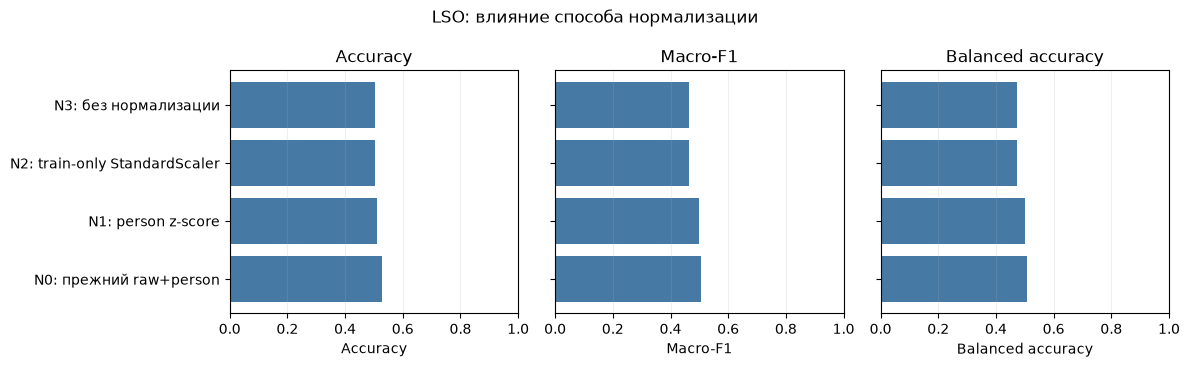

In [11]:
legacy_folds, legacy_pred = evaluate_lso(
    'N0: прежний raw+person', X_legacy, 'Random Forest', 7,
    train_scaling=False)
old_lso = previous_folds.query("experiment == '8_LSO'").sort_values('fold')
np.testing.assert_allclose(legacy_folds['accuracy'], old_lso['accuracy'], atol=1e-10)
person_folds, person_pred = evaluate_lso(
    'N1: person z-score', X_person, 'Random Forest', 7,
    train_scaling=False)
train_folds, train_pred = evaluate_lso(
    'N2: train-only StandardScaler', X_raw, 'Random Forest', 7,
    train_scaling=True)
raw_folds, raw_pred = evaluate_lso(
    'N3: без нормализации', X_raw, 'Random Forest', 7,
    train_scaling=False)
norm_table = pd.DataFrame([summary(folds) for folds in
                           [legacy_folds, person_folds, train_folds, raw_folds]])
display(norm_table.round(3))
display(Markdown(
    f'Среди схем с одинаковыми 150 признаками персональная нормализация дала '
    f'наибольший macro-F1 (**{person_folds["macro_f1"].mean():.3f}**), '
    'но использовала сигналы тестовых людей. Train-only и отсутствие '
    'нормализации сравниваются без такой утечки.'
))
metric_plot(norm_table, 'LSO: влияние способа нормализации', '01_normalization')

In [12]:
indexed_norm = norm_table.set_index('Конфигурация')
safe = indexed_norm.loc['N2: train-only StandardScaler']
personal = indexed_norm.loc['N1: person z-score']
raw = indexed_norm.loc['N3: без нормализации']
display(Markdown(
    f'При одинаковых 150 признаках train-only нормализация дала '
    f'accuracy **{safe["Accuracy"]:.1%}**, персональная — '
    f'**{personal["Accuracy"]:.1%}**, без нормализации — '
    f'**{raw["Accuracy"]:.1%}**. Разница train-only и персонального '
    f'варианта по macro-F1 составила **{safe["Macro-F1"] - personal["Macro-F1"]:+.3f}**. '
    'Даже если персональный вариант окажется выше, его оценка использует '
    'распределение тестовых сигналов. Для сохранённого артефакта ниже '
    'используется только train-only StandardScaler.'
))

При одинаковых 150 признаках train-only нормализация дала accuracy **50.2%**, персональная — **51.2%**, без нормализации — **50.2%**. Разница train-only и персонального варианта по macro-F1 составила **-0.034**. Даже если персональный вариант окажется выше, его оценка использует распределение тестовых сигналов. Для сохранённого артефакта ниже используется только train-only StandardScaler.

## 4. Сравнение алгоритмов

Random Forest, Logistic Regression и Extra Trees получают те же 150 сырых PS-признаков, `StandardScaler` по обучению и те же пять LSO-фолдов. Параметры этого сравнения зафиксированы заранее: 100 деревьев и 7 признаков в узле у лесов, `C=1` у логистической регрессии. Отдельный внутренний выбор для сохранённой модели выполнен в разделе 2.

M2: Logistic Regression · fold 1: accuracy 47.5%, macro-F1 0.445


M2: Logistic Regression · fold 2: accuracy 39.5%, macro-F1 0.407


M2: Logistic Regression · fold 3: accuracy 50.3%, macro-F1 0.510


M2: Logistic Regression · fold 4: accuracy 44.7%, macro-F1 0.469


M2: Logistic Regression · fold 5: accuracy 37.7%, macro-F1 0.307


...

M3: Extra Trees · fold 3: accuracy 48.3%, macro-F1 0.481


M3: Extra Trees · fold 4: accuracy 46.0%, macro-F1 0.436


M3: Extra Trees · fold 5: accuracy 40.8%, macro-F1 0.244


,Конфигурация,Признаков,Accuracy,Macro-F1,Balanced accuracy,ROC-AUC OvR,ROC-AUC фолдов,"Обучение, с","Предсказание, мс","Размер, МБ"
0,N2: train-only StandardScaler,150,0.502,0.464,0.472,0.798,5,1.271,72.427,30.888
1,M2: Logistic Regression,150,0.439,0.428,0.467,0.786,5,1.392,5.718,0.009
2,M3: Extra Trees,150,0.466,0.396,0.370,0.786,5,0.468,68.705,81.192


При одинаковых 150 признаках и разделениях Random Forest получил macro-F1 **0.464**; Logistic Regression — **0.428**, Extra Trees — **0.396**.

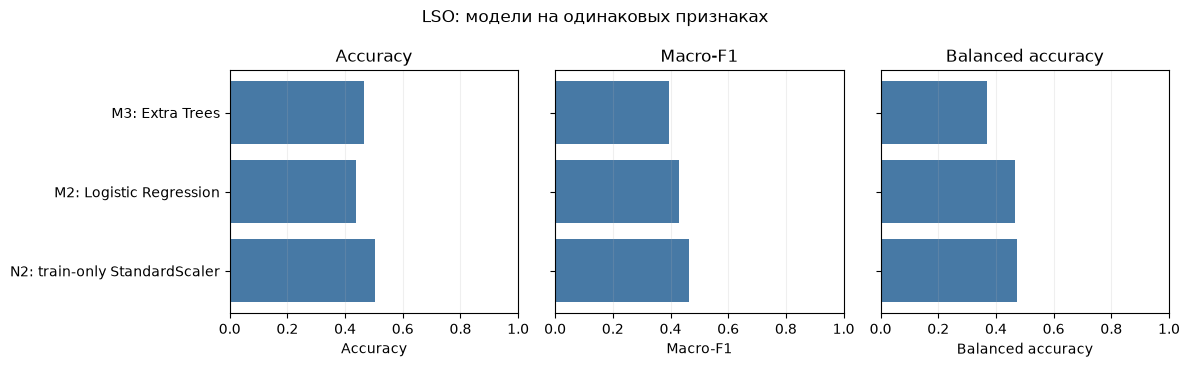

In [13]:
rf_folds, rf_pred = train_folds, train_pred
lr_folds, lr_pred = evaluate_lso(
    'M2: Logistic Regression', X_raw, 'Logistic Regression', 1.0,
    train_scaling=True)
et_folds, et_pred = evaluate_lso(
    'M3: Extra Trees', X_raw, 'Extra Trees', 7,
    train_scaling=True)
model_table = pd.DataFrame([summary(folds) for folds in
                            [rf_folds, lr_folds, et_folds]])
display(model_table.round(3))
display(Markdown(
    f'При одинаковых 150 признаках и разделениях Random Forest получил '
    f'macro-F1 **{rf_folds["macro_f1"].mean():.3f}**; '
    f'Logistic Regression — **{lr_folds["macro_f1"].mean():.3f}**, '
    f'Extra Trees — **{et_folds["macro_f1"].mean():.3f}**.'
))
metric_plot(model_table, 'LSO: модели на одинаковых признаках', '02_models')

In [14]:
best_model_lso = model_table.loc[model_table['Macro-F1'].idxmax()]
display(Markdown(
    f'В описательном пятифолдовом LSO наибольший macro-F1 показала '
    f'**{best_model_lso["Конфигурация"]}** ({best_model_lso["Macro-F1"]:.3f}). '
    f'Её среднее время предсказания тестового фолда — '
    f'**{best_model_lso["Предсказание, мс"]:.1f} мс**, размер '
    f'сериализованной модели — **{best_model_lso["Размер, МБ"]:.1f} МБ**. '
    f'Это сравнение не меняет ранее выбранный лабораторный артефакт '
    f'({selected_algorithm}, {chosen_feature}): иначе внешние тестовые '
    'группы стали бы частью подбора.'
))

В описательном пятифолдовом LSO наибольший macro-F1 показала **N2: train-only StandardScaler** (0.464). Её среднее время предсказания тестового фолда — **72.4 мс**, размер сериализованной модели — **30.9 МБ**. Это сравнение не меняет ранее выбранный лабораторный артефакт (Random Forest, без каденса): иначе внешние тестовые группы стали бы частью подбора.

## 5. Вклад каналов

От полного набора по очереди удаляются магнитометр, свободное ускорение с результирующей величиной или частота циклов. Меняется один компонент; модель, разделения и остальные каналы остаются теми же. Совместные удаления здесь не проверяются.

F: без магнитометра · fold 1: accuracy 48.6%, macro-F1 0.385


F: без магнитометра · fold 2: accuracy 49.5%, macro-F1 0.475


F: без магнитометра · fold 3: accuracy 43.4%, macro-F1 0.455


F: без магнитометра · fold 4: accuracy 46.4%, macro-F1 0.467


F: без магнитометра · fold 5: accuracy 36.2%, macro-F1 0.295


...

F: без каденса · fold 3: accuracy 55.5%, macro-F1 0.561


F: без каденса · fold 4: accuracy 50.9%, macro-F1 0.514


F: без каденса · fold 5: accuracy 39.7%, macro-F1 0.297


,Конфигурация,Признаков,Accuracy,Macro-F1,Balanced accuracy,ROC-AUC OvR,ROC-AUC фолдов,"Обучение, с","Предсказание, мс","Размер, МБ"
0,N2: train-only StandardScaler,150,0.502,0.464,0.472,0.798,5,1.271,72.427,30.888
1,F: без магнитометра,120,0.448,0.415,0.417,0.782,5,1.131,66.548,33.292
2,F: без свободного ускорения,110,0.481,0.444,0.450,0.792,5,1.061,57.676,30.879
3,F: без каденса,140,0.505,0.470,0.476,0.812,5,1.244,61.564,30.842


Строки изменяют только один компонент полного набора. Из трёх удалений наибольшее снижение macro-F1 наблюдалось без магнитометра; точные разницы приведены ниже.

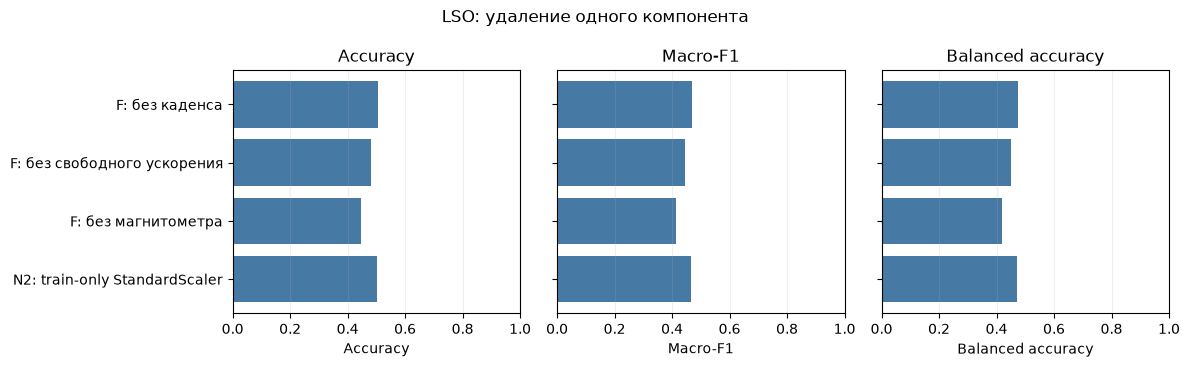

На диаграмме заметно, что удаление магнитометра ухудшает все три показателя. Разница без каденса мала и не подтверждает полезность его удаления для каждого нового участника.

In [15]:
feature_fold_tables = [rf_folds]
feature_predictions = [rf_pred]
for feature_name in ['без магнитометра', 'без свободного ускорения',
                     'без каденса']:
    indices = FEATURE_SETS[feature_name]
    folds, predictions = evaluate_lso(
        f'F: {feature_name}', X_raw[:, indices], 'Random Forest', 7,
        train_scaling=True)
    feature_fold_tables.append(folds)
    feature_predictions.append(predictions)
feature_table = pd.DataFrame([summary(folds) for folds in feature_fold_tables])
display(feature_table.round(3))
display(Markdown(
    'Строки изменяют только один компонент полного набора. Из трёх удалений '
    'наибольшее снижение macro-F1 наблюдалось без магнитометра; '
    'точные разницы приведены ниже.'
))
metric_plot(feature_table, 'LSO: удаление одного компонента', '03_features')
display(Markdown(
    'На диаграмме заметно, что удаление магнитометра ухудшает все три '
    'показателя. Разница без каденса мала и не подтверждает полезность '
    'его удаления для каждого нового участника.'
))

In [16]:
full = feature_table.iloc[0]
feature_changes = feature_table.iloc[1:].copy()
for metric in ['Accuracy', 'Macro-F1', 'Balanced accuracy']:
    feature_changes['Δ ' + metric] = feature_changes[metric] - full[metric]
display(feature_changes[['Конфигурация', 'Признаков', 'Δ Accuracy',
                         'Δ Macro-F1', 'Δ Balanced accuracy']].round(3))
largest_feature_loss = feature_changes.loc[feature_changes['Δ Macro-F1'].idxmin()]
display(Markdown(
    f'Наибольшее снижение macro-F1 при удалении одного компонента '
    f'наблюдалось в **{largest_feature_loss["Конфигурация"]}** '
    f'({largest_feature_loss["Δ Macro-F1"]:+.3f}). '
    'Эти различия описывают данный набор и фиксированный лес; они не '
    'доказывают, что канал причинно определяет рельеф. Внутренний выбор '
    f'лабораторного набора **{chosen_feature}** был сделан отдельно, до '
    'просмотра этих внешних результатов.'
))

,Конфигурация,Признаков,Δ Accuracy,Δ Macro-F1,Δ Balanced accuracy
1,F: без магнитометра,120,-0.054,-0.049,-0.055
2,F: без свободного ускорения,110,-0.021,-0.020,-0.022
3,F: без каденса,140,0.003,0.006,0.004


Наибольшее снижение macro-F1 при удалении одного компонента наблюдалось в **F: без магнитометра** (-0.049). Эти различия описывают данный набор и фиксированный лес; они не доказывают, что канал причинно определяет рельеф. Внутренний выбор лабораторного набора **без каденса** был сделан отдельно, до просмотра этих внешних результатов.

## 6. Ошибки по классам и участникам

Матрицы ошибок собирают предсказания всех пяти внешних фолдов. Основные метрики в сводке — средние по фолдам. Отдельно показана матрица выбранной модели на четырёх отложенных людях. ROC-AUC OvR считается по вероятностям только там, где в тесте есть все восемь классов.

experiment,M2: Logistic Regression,M3: Extra Trees,N2: train-only StandardScaler
participant,,,
P1,0.34,0.36,0.34
P2,0.53,0.52,0.57
P3,0.32,0.49,0.45
P4,0.36,0.35,0.47
P5,0.41,0.72,0.66
P6,0.48,0.42,0.51
P7,0.44,0.56,0.59
P8,0.36,0.56,0.50
P9,0.46,0.44,0.56


Таблица показывает большой разброс accuracy между людьми. Среднее по фолдам не описывает одинаково хорошо каждого участника; далее тот же разброс показан на графике.

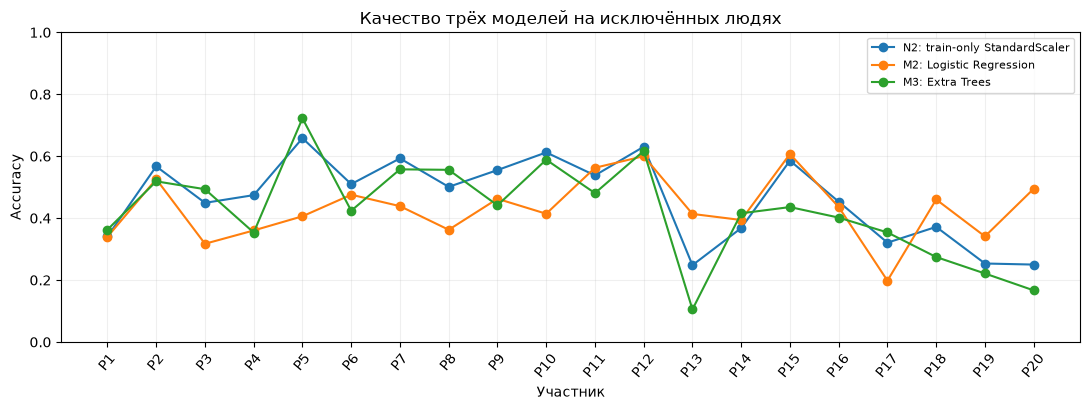

Линии пересекаются: преимущество модели в среднем не означает её превосходства для каждого человека. Поэтому сравнение дополнено матрицами ошибок и минимумом accuracy по участникам.

In [17]:
all_folds = pd.concat(FOLD_TABLES, ignore_index=True)
all_predictions = pd.concat(PREDICTION_TABLES, ignore_index=True)
participant_rows = []
for (experiment, person), part in all_predictions.groupby(['experiment', 'participant']):
    participant_rows.append({
        'experiment': experiment, 'participant': person,
        'test_cycles': len(part),
        'accuracy': accuracy_score(part['true'], part['predicted']),
        'macro_f1': f1_score(part['true'], part['predicted'], labels=LABELS,
                             average='macro', zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(part['true'], part['predicted'])})
participant_results = pd.DataFrame(participant_rows)
selected_names = ['N2: train-only StandardScaler', 'M2: Logistic Regression',
                  'M3: Extra Trees']
display(participant_results[participant_results['experiment'].isin(selected_names)]
        .pivot(index='participant', columns='experiment', values='accuracy')
        .reindex(people).round(2))
display(Markdown(
    'Таблица показывает большой разброс accuracy между людьми. Среднее по '
    'фолдам не описывает одинаково хорошо каждого участника; далее тот же '
    'разброс показан на графике.'
))
fig, ax = plt.subplots(figsize=(11, 4.2))
for name in selected_names:
    part = participant_results[participant_results['experiment'].eq(name)]
    values = part.set_index('participant')['accuracy'].reindex(people)
    ax.plot(people, values, marker='o', label=name)
ax.set(xlabel='Участник', ylabel='Accuracy', ylim=(0, 1),
       title='Качество трёх моделей на исключённых людях')
ax.tick_params(axis='x', labelrotation=50)
ax.legend(fontsize=8)
ax.grid(alpha=.2)
fig.tight_layout()
display(fig)
fig.savefig(OUTPUT_DIR / 'figures' / '04_participants.png', dpi=160)
fig.savefig(OUTPUT_DIR / 'figures' / '04_participants.svg')
plt.close(fig)
display(Markdown(
    'Линии пересекаются: преимущество модели в среднем не означает её '
    'превосходства для каждого человека. Поэтому сравнение дополнено '
    'матрицами ошибок и минимумом accuracy по участникам.'
))

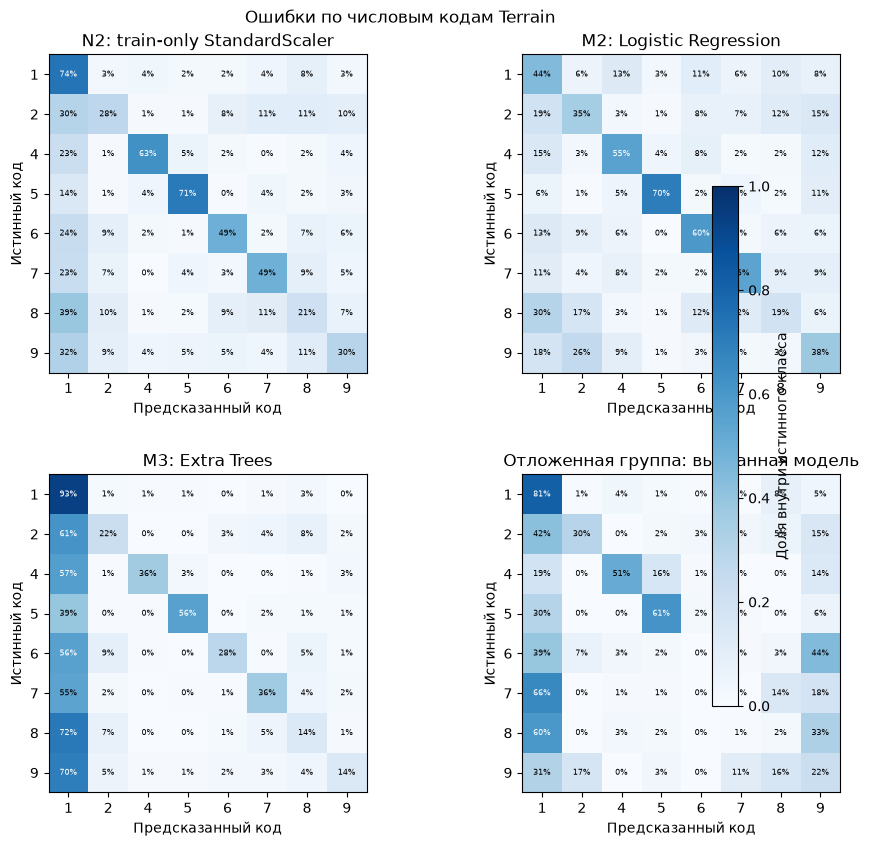

Матрицы показывают, какие числовые коды Terrain смешиваются. Нормировка по строкам нужна из-за неодинакового числа циклов в классах; диагональные доли приведены численно в следующей таблице.

experiment,M2: Logistic Regression,M3: Extra Trees,N2: train-only StandardScaler,Отложенная группа: выбранная модель
class,,,,
1,0.44,0.93,0.74,0.81
2,0.35,0.22,0.28,0.30
4,0.55,0.36,0.63,0.51
5,0.70,0.56,0.71,0.61
6,0.60,0.28,0.49,0.00
7,0.55,0.36,0.49,0.00
8,0.19,0.14,0.21,0.02
9,0.38,0.14,0.30,0.22


На отложенной группе хуже всего распознаётся код **6**: recall **0.0%**. Это ограничивает пригодность модели даже при умеренной общей accuracy.

In [18]:
confusion_rows = []
recall_rows = []
def confusion_for(name, truth, predicted):
    matrix = confusion_matrix(truth, predicted, labels=LABELS)
    for i, true_code in enumerate(LABELS):
        total = matrix[i].sum()
        recall_rows.append({'experiment': name, 'class': true_code,
                            'test_cycles': int(total),
                            'recall': matrix[i, i] / total if total else np.nan})
        for j, predicted_code in enumerate(LABELS):
            confusion_rows.append({'experiment': name, 'true': true_code,
                                   'predicted': predicted_code,
                                   'cycles': int(matrix[i, j])})
    return matrix

model_predictions = [train_pred, lr_pred, et_pred]
matrices = [confusion_for(name, part['true'], part['predicted'])
            for name, part in zip(selected_names, model_predictions)]
matrices.append(confusion_for('Отложенная группа: выбранная модель',
                              y[holdout], holdout_predicted))
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name, matrix in zip(axes.flat,
    selected_names + ['Отложенная группа: выбранная модель'], matrices):
    totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float),
                           where=totals > 0)
    image = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    ax.set(xticks=range(8), yticks=range(8),
           xticklabels=LABELS, yticklabels=LABELS,
           xlabel='Предсказанный код', ylabel='Истинный код', title=name)
    for i in range(8):
        for j in range(8):
            ax.text(j, i, f'{normalized[i, j]:.0%}', ha='center', va='center',
                    fontsize=6, color='white' if normalized[i, j] > .55 else 'black')
fig.colorbar(image, ax=axes.ravel().tolist(), label='Доля внутри истинного класса',
             shrink=.75)
fig.suptitle('Ошибки по числовым кодам Terrain')
fig.subplots_adjust(top=.93, hspace=.32, wspace=.25)
display(fig)
fig.savefig(OUTPUT_DIR / 'figures' / '05_confusion.png', dpi=160)
fig.savefig(OUTPUT_DIR / 'figures' / '05_confusion.svg')
plt.close(fig)
display(Markdown(
    'Матрицы показывают, какие числовые коды Terrain смешиваются. '
    'Нормировка по строкам нужна из-за неодинакового числа циклов в классах; '
    'диагональные доли приведены численно в следующей таблице.'
))
class_recall = pd.DataFrame(recall_rows)
confusion_table = pd.DataFrame(confusion_rows)
display(class_recall.pivot(index='class', columns='experiment',
                           values='recall').round(2))
holdout_recall = class_recall[
    class_recall['experiment'].eq('Отложенная группа: выбранная модель')
]
weakest = holdout_recall.loc[holdout_recall['recall'].idxmin()]
display(Markdown(
    f'На отложенной группе хуже всего распознаётся код '
    f'**{int(weakest["class"])}**: recall **{weakest["recall"]:.1%}**. '
    'Это ограничивает пригодность модели даже при умеренной общей accuracy.'
))

In [19]:
spread = participant_results[participant_results['experiment'].isin(selected_names)]
spread_table = spread.groupby('experiment')['accuracy'].agg(
    ['mean', 'median', 'min', 'max', 'std']).reindex(selected_names)
display(spread_table.round(3))
best_stability = spread_table['min'].idxmax()
display(Markdown(
    f'Лучший минимальный результат среди трёх заранее заданных моделей '
    f'наблюдался у **{best_stability}** '
    f'({spread_table.loc[best_stability, "min"]:.1%}). '
    'Средние по людям и по фолдам различаются, поскольку у людей неодинаковое '
    'число циклов. Ни одна матрица ошибок не устраняет неопределённость '
    'значений кодов 8/9 в документации набора.'
))

,mean,median,min,max,std
experiment,,,,,
N2: train-only StandardScaler,0.464,0.488,0.248,0.658,0.133
M2: Logistic Regression,0.430,0.425,0.198,0.607,0.100
M3: Extra Trees,0.424,0.430,0.105,0.722,0.154


Лучший минимальный результат среди трёх заранее заданных моделей наблюдался у **N2: train-only StandardScaler** (24.8%). Средние по людям и по фолдам различаются, поскольку у людей неодинаковое число циклов. Ни одна матрица ошибок не устраняет неопределённость значений кодов 8/9 в документации набора.

,Группа,Конфигурация,Признаков,Accuracy,Macro-F1,Balanced accuracy,ROC-AUC OvR,ROC-AUC фолдов,"Обучение, с","Предсказание, мс","Размер, МБ"
0,Нормализация,N0: прежний raw+person,300,0.527,0.505,0.508,0.822,5,1.125,55.808,30.935
1,Нормализация,N1: person z-score,150,0.512,0.498,0.500,0.820,5,1.311,70.762,31.376
2,Нормализация,N2: train-only StandardScaler,150,0.502,0.464,0.472,0.798,5,1.271,72.427,30.888
3,Нормализация,N3: без нормализации,150,0.502,0.464,0.472,0.798,5,1.484,81.925,30.884
4,Алгоритм,M2: Logistic Regression,150,0.439,0.428,0.467,0.786,5,1.392,5.718,0.009
5,Алгоритм,M3: Extra Trees,150,0.466,0.396,0.370,0.786,5,0.468,68.705,81.192
6,Каналы,F: без магнитометра,120,0.448,0.415,0.417,0.782,5,1.131,66.548,33.292
7,Каналы,F: без свободного ускорения,110,0.481,0.444,0.450,0.792,5,1.061,57.676,30.879
8,Каналы,F: без каденса,140,0.505,0.470,0.476,0.812,5,1.244,61.564,30.842


Сводка содержит все заранее заданные конфигурации: девять строк на одинаковых внешних LSO-группах. Исторический вариант использует 300 признаков, остальные — 110–150. Время и размер даны для обученных фолдов.

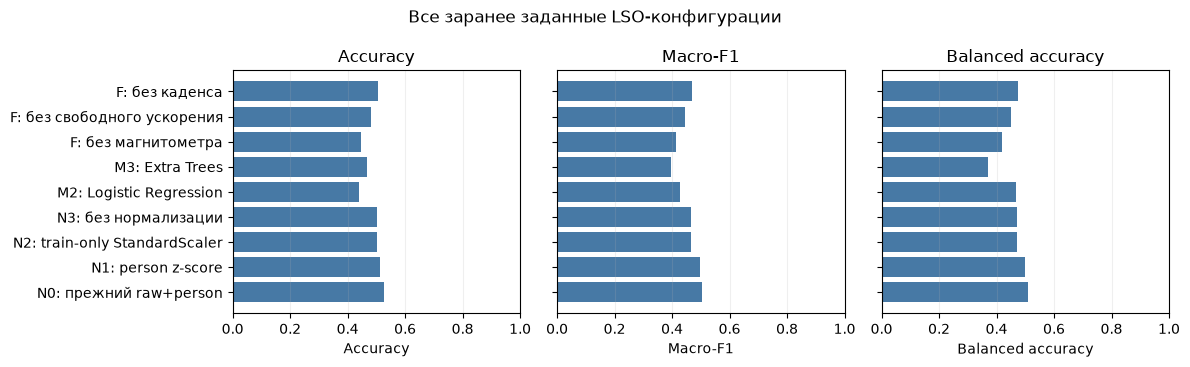

In [20]:
all_summaries = pd.DataFrame([summary(folds) for folds in FOLD_TABLES])
all_summaries['Группа'] = [
    'Нормализация' if name.startswith('N') else
    'Алгоритм' if name.startswith('M') else 'Каналы'
    for name in all_summaries['Конфигурация']]
display(all_summaries[['Группа', 'Конфигурация', 'Признаков', 'Accuracy',
                       'Macro-F1', 'Balanced accuracy', 'ROC-AUC OvR',
                       'ROC-AUC фолдов', 'Обучение, с',
                       'Предсказание, мс', 'Размер, МБ']].round(3))
display(Markdown(
    'Сводка содержит все заранее заданные конфигурации: девять строк на '
    'одинаковых внешних LSO-группах. Исторический вариант использует 300 '
    'признаков, остальные — 110–150. Время и размер даны для обученных фолдов.'
))
metric_plot(all_summaries, 'Все заранее заданные LSO-конфигурации',
            '06_overall_comparison')

In [21]:
old_group5 = previous_folds.query("experiment == '8_LSO' and fold == 5").iloc[0]
display(Markdown(
    f'На отложенной группе старая схема raw+person дала accuracy '
    f'**{old_group5["accuracy"]:.1%}**, выбранная модель — '
    f'**{holdout_scores["accuracy"]:.1%}** и macro-F1 '
    f'**{holdout_scores["macro_f1"]:.3f}**. '
    'Прямым подтверждением улучшения это сравнение не служит: '
    'старая модель использовала сигналы тестового человека при нормализации, '
    'а данные этих участников изучались на предыдущих этапах. '
    f'Для лабораторной выбран **{selected_algorithm}** '
    f'({chosen_feature}, {len(chosen_indices)} признаков). '
    'Для надёжной оценки нужна новая когорта.'
))

На отложенной группе старая схема raw+person дала accuracy **38.2%**, выбранная модель — **41.4%** и macro-F1 **0.299**. Прямым подтверждением улучшения это сравнение не служит: старая модель использовала сигналы тестового человека при нормализации, а данные этих участников изучались на предыдущих этапах. Для лабораторной выбран **Random Forest** (без каденса, 140 признаков). Для надёжной оценки нужна новая когорта.

## 8. Ограничения и воспроизводимость

Сохранённый `TerrainPredictor` зависит от установленного модуля `research_graph.models.terrain_predictor`. Загружается только доверенный артефакт. Сторона протеза при обработке PS CSV задаётся явно. Метки отложенной группы не использовались при обучении или выборе модели в этом ноутбуке. Участники уже анализировались на ранних этапах проекта, что ограничивает независимость этой проверки.

In [22]:
fold_assignments = cycles[['participant', 'recording_group', 'trial',
                           'step', 'run']].copy()
fold_assignments['fold'] = fold_number
holdout_detail.to_csv(OUTPUT_DIR / 'holdout_predictions.csv', index=False)
all_summaries.to_csv(OUTPUT_DIR / 'experiment_results.csv', index=False)
all_folds.to_csv(OUTPUT_DIR / 'fold_results.csv', index=False)
all_predictions.to_csv(OUTPUT_DIR / 'predictions.csv', index=False)
participant_results.to_csv(OUTPUT_DIR / 'participant_results.csv', index=False)
class_recall.to_csv(OUTPUT_DIR / 'class_recall.csv', index=False)
confusion_table.to_csv(OUTPUT_DIR / 'confusion_matrices.csv', index=False)
inner_models.to_csv(OUTPUT_DIR / 'inner_model_selection.csv', index=False)
inner_features.to_csv(OUTPUT_DIR / 'inner_feature_selection.csv', index=False)
fold_assignments.to_csv(OUTPUT_DIR / 'fold_assignments.csv', index=False)
pd.DataFrame(excluded).to_csv(OUTPUT_DIR / 'excluded_files.csv', index=False)
run_config = {
    'date': datetime.now().astimezone().isoformat(timespec='seconds'),
    'dataset_doi': manifest['dataset_doi'],
    'dataset_sha256': manifest['dataset_sha256'],
    'source_dir': str(DATA_DIR),
    'people': people,
    'lso_groups': LSO_GROUPS,
    'heldout_group': holdout_people,
    'development_people': sorted(set(physical_ids[development]),
                                 key=lambda p: int(p[1:])),
    'inner_model_grid': MODEL_GRID,
    'selection_metric': 'mean_macro_f1_on_four_development_group_folds',
    'feature_selection_rule': 'within_0.005_of_best_macro_f1_then_fewest_features',
    'selected_algorithm': selected_algorithm,
    'selected_parameter': selected_parameter,
    'selected_feature_set': chosen_feature,
    'selected_feature_names': [FEATURE_NAMES[index] for index in chosen_indices],
    'normalization': 'StandardScaler_fit_inside_training_Pipeline',
    'sampling_hz_assumed': 100,
    'model_artifact': str(model_path),
    'model_sha256': artifact_metadata['artifact_sha256'],
    'holdout_metrics': holdout_scores,
    'versions': versions,
    'python': platform.python_version(),
}
(OUTPUT_DIR / 'experiment_config.json').write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.Series(versions, name='Версия').to_frame())
print('Таблицы, графики, конфигурация и модель:', OUTPUT_DIR)

,Версия
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
joblib,1.6.0
matplotlib,3.11.2


Версии библиотек соответствуют среде, в которой создана модель. Для загрузки нужны совместимые версии scikit-learn, NumPy и SciPy.

Таблицы, графики, конфигурация и модель: ~/research-publication-data\artifacts\reports\model_validation
